# 03. Recovery study

Repeated datasets of 50,000 chats from the `baseline` preset. Each estimator is
fitted to each dataset. The truth comes from one million simulated chats per
regime. Regenerate with:

```bash
uv run python tools/recovery.py --preset baseline --reps 20
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "tools"))
from recovery import summarise

pd.set_option("display.width", 120)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

In [3]:
summary = summarise(Path("../results/recovery_baseline.csv"),
                    Path("../results/truth_baseline.csv"))
print("replicates:", int(summary["reps"].min()))
(summary[["rd_true", "rd_mean", "bias", "sd", "rmse"]] * 1000).round(2)

replicates: 20


rd_true  rd_mean  bias    sd  rmse
estimator              regime                                                
count_all              never_any             -5.69   -10.33 -4.64  0.59  4.67
                       never_escalation      -4.09    -8.89 -4.81  0.45  4.83
                       never_requeue         -3.09    -0.68  2.41  0.34  2.44
                       never_shift_change    -1.32    -0.04  1.28  0.24  1.30
                       never_transfer        -0.45    -2.19 -1.74  0.42  1.79
count_window           never_any             -5.69    -6.96 -1.27  0.54  1.37
                       never_escalation      -4.09    -3.25  0.84  0.30  0.89
                       never_requeue         -3.09    -2.02  1.07  0.32  1.11
                       never_shift_change    -1.32    -0.29  1.03  0.23  1.06
                       never_transfer        -0.45    -2.82 -2.37  0.41  2.40
count_window_sentiment never_any             -5.69    -6.99 -1.30  0.57  1.41
                       never_escalation      -4.09    -3.27  0.82  0.31  0.87
                       never_requeue         -3.09    -2.02  1.07  0.33  1.11
                       never_shift_change    -1.32    -0.30  1.03  0.24  1.05
                       never_transfer        -0.45    -2.84 -2.39  0.41  2.42
gformula               never_any             -5.69    -4.73  0.96  1.07  1.42
                       never_escalation      -4.09    -3.80  0.29  0.39  0.48
                       never_requeue         -3.09    -2.92  0.17  0.33  0.36
                       never_shift_change    -1.32    -1.07  0.25  0.26  0.36
                       never_transfer        -0.45    -0.69 -0.24  0.55  0.59
ipw                    never_any             -5.69    -6.50 -0.81  3.67  3.66
                       never_escalation      -4.09    -4.45 -0.37  0.46  0.58
                       never_requeue         -3.09    -3.07  0.02  0.41  0.40
                       never_shift_change    -1.32    -0.97  0.36  0.34  0.49
                       never_transfer        -0.45    -1.00 -0.55  1.63  1.68
ipw_trunc99            never_any             -5.69    -8.47 -2.77  1.06  2.96
                       never_escalation      -4.09    -5.18 -1.10  0.44  1.18
                       never_requeue         -3.09    -3.27 -0.18  0.39  0.42
                       never_shift_change    -1.32    -0.83  0.50  0.24  0.55
                       never_transfer        -0.45    -1.51 -1.06  0.87  1.35
pooled_hazard          never_any             -5.69    -2.66  3.04  0.70  3.11
                       never_escalation      -4.09    -1.06  3.03  0.61  3.09
                       never_requeue         -3.09    -0.60  2.49  0.35  2.52
                       never_shift_change    -1.32    -0.20  1.13  0.22  1.15
                       never_transfer        -0.45    -0.93 -0.48  0.40  0.62

Root mean squared error per 1,000 chats, by estimator and regime.

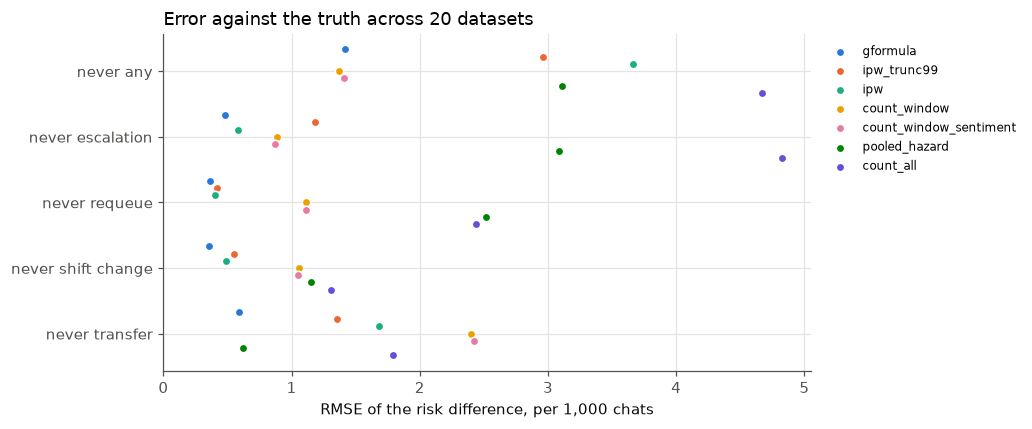

In [4]:
rmse = (summary["rmse"] * 1000).unstack("estimator")
order = rmse.mean().sort_values().index
rmse = rmse[order]
fig, ax = plt.subplots(figsize=(9.5, 4))
y = np.arange(len(rmse.index))
step = 0.11
for j, name in enumerate(order):
    off = (j - (len(order) - 1) / 2) * step
    ax.scatter(rmse[name], y + off, s=30, color=SERIES[j % len(SERIES)], label=name,
               edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(y, [s.replace("_", " ") for s in rmse.index])
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("RMSE of the risk difference, per 1,000 chats")
ax.set_title(f"Error against the truth across {int(summary['reps'].min())} datasets", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

Relative bias: the mean estimate as a share of the true effect. 100% means
unbiased on average.

In [5]:
rel = (summary["rd_mean"] / summary["rd_true"] * 100).unstack("estimator")[order]
rel.round(0)

estimator,gformula,ipw_trunc99,ipw,count_window,count_window_sentiment,pooled_hazard,count_all
regime,,,,,,,
never_any,83.0,149.0,114.0,122.0,123.0,47.0,181.0
never_escalation,93.0,127.0,109.0,79.0,80.0,26.0,218.0
never_requeue,95.0,106.0,99.0,65.0,65.0,19.0,22.0
never_shift_change,81.0,63.0,73.0,22.0,22.0,15.0,3.0
never_transfer,153.0,335.0,222.0,625.0,631.0,207.0,487.0
